# ParkVision AI — Data Preprocessing & Model Training
**SA-1 · Scenario 1: ParkVision AI (UrbanFlow AI Pvt. Ltd. / ParkSmart AI)**

Trains a MobileNetV2 slot-occupancy classifier (Occupied / Empty) on the
[PKLot dataset](https://www.inf.ufpr.br/vri/databases/PKLot.tar.gz) and
evaluates it, per Steps 2–3 of the assignment brief.

**Before running:** `Runtime -> Change runtime type -> T4 GPU` (training is
much slower on CPU).

Covers:
1. Download & inspect the PKLot dataset
2. Build a balanced, preprocessed subset (resize, augment, 70/15/15 split)
3. Train a MobileNetV2 transfer-learning classifier
4. Evaluate (accuracy, confusion matrix, classification report)
5. Save the model for use in the Streamlit app (`app.py`)


## Step 1 recap — problem definition

- **Input:** a parking-lot image (or, for training, a cropped single-slot image)
- **Output:** slot-wise status, `Occupied` or `Empty`
- **Approach chosen:** crop-based binary **classification** with MobileNetV2 (the brief's suggested classification route — simpler to get right than full detection, and PKLot already ships per-slot cropped, labeled images)
- **Known challenges:** shadows/lighting, partial occlusion, weather variation (PKLot conveniently covers Sunny/Cloudy/Rainy, which is exactly why it's the reference dataset for this scenario)

In [ ]:
!pip install -q opencv-python-headless scikit-learn kaggle

import os, json, random, shutil, zipfile
from pathlib import Path

import numpy as np
import cv2
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

print("TensorFlow:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)


TensorFlow: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Step 2 — Download the PKLot dataset

**Option A — Kaggle (recommended, fastest):**
1. Go to kaggle.com -> your profile -> *Settings* -> *API* -> *Create New Token*.
   This downloads a `kaggle.json` file.
2. Run the cell below and upload that `kaggle.json` when prompted.

**Option B — official UFPR mirror (no Kaggle account needed):**
Skip to the commented-out `wget` cell further down if you'd rather pull the
dataset directly from the paper's authors.

> The exact Kaggle dataset listing can move or get re-uploaded under a new
> slug over time — if `ammarnassanalhajali/pklot-dataset` below 404s, search
> ["PKLot dataset" on Kaggle](https://www.kaggle.com/datasets?search=pklot)
> for the current one and swap the slug in the `!kaggle datasets download`
> line.


In [ ]:
from google.colab import files

print("Upload your kaggle.json (Kaggle -> Settings -> API -> Create New Token):")
uploaded = files.upload()

os.makedirs("/root/.kaggle", exist_ok=True)
shutil.move("kaggle.json", "/root/.kaggle/kaggle.json")
os.chmod("/root/.kaggle/kaggle.json", 0o600)


In [2]:
   import os, shutil
   os.makedirs("/root/.kaggle", exist_ok=True)
   shutil.copy("/content/kaggle.json", "/root/.kaggle/kaggle.json")
   os.chmod("/root/.kaggle/kaggle.json", 0o600)
   print("Kaggle key set up")

Kaggle key set up


In [4]:
# Kaggle mirror of PKLot. If this slug no longer resolves, search Kaggle for
# "PKLot dataset" and swap it in here.
KAGGLE_SLUG = "ammarnassanalhajali/pklot-dataset"

!kaggle datasets download -d {KAGGLE_SLUG} -p /content/pklot_raw --unzip


Dataset URL: https://www.kaggle.com/datasets/ammarnassanalhajali/pklot-dataset
License(s): unknown
100% 843M/843M [00:07<00:00, 125MB/s]



In [5]:
import json, glob, random, cv2
from pathlib import Path

# find the TEST split's COCO json automatically
cands = [p for p in glob.glob('/content/**/*.json', recursive=True)
         if Path(p).parent.name.lower() == 'test']
assert cands, "No json found in a 'test' folder - send me the error"
ann_path = cands[0]
root = Path(ann_path).parent
coco = json.load(open(ann_path))
cats = {c['id']: c['name'].lower() for c in coco['categories']}
keep = {i for i, n in cats.items() if 'occupied' in n or 'empty' in n}
by_img = {}
for a in coco['annotations']:
    if a['category_id'] in keep:
        by_img.setdefault(a['image_id'], []).append(a)
images = {im['id']: im for im in coco['images']}
good = sorted(i for i, anns in by_img.items() if len(anns) >= 20)

def make_photo(seed):
    rng = random.Random(seed)
    img_id = rng.choice(good)
    info, anns = images[img_id], by_img[img_id]
    img = cv2.imread(str(root / info['file_name']))
    slots, occ, emp = [], 0, 0
    for k, a in enumerate(anns):
        x, y, w, h = [int(round(v)) for v in a['bbox']]
        slots.append({"id": k, "x": x, "y": y, "w": w, "h": h})
        if 'occupied' in cats[a['category_id']]: occ += 1
        else: emp += 1
    cv2.imwrite(f'real_lot_{seed}.jpg', img)
    json.dump(slots, open(f'real_slot_positions_{seed}.json', 'w'))
    print(f"Photo {seed}: {len(slots)} slots | TRUE occupied={occ}, empty={emp} | {info['file_name']}")

for s in [2, 3, 4, 5]:
    make_photo(s)

!zip -q photos.zip real_lot_*.jpg real_slot_positions_*.json
from google.colab import files
files.download('photos.zip')

Photo 2: 40 slots | TRUE occupied=7, empty=33 | 2013-04-13_17_45_13_jpg.rf.186e7a6b927c306bfcd445dd1a02ef85.jpg
Photo 3: 28 slots | TRUE occupied=25, empty=3 | 2012-12-11_17_21_09_jpg.rf.6ab72694faa919b040b4951edad5830a.jpg
Photo 4: 100 slots | TRUE occupied=91, empty=9 | 2012-11-09_08_16_36_jpg.rf.6a0edd2e317208128cdba9473213c872.jpg
Photo 5: 40 slots | TRUE occupied=39, empty=1 | 2013-04-12_16_00_11_jpg.rf.72ca39f1a58ea032a5a562fbe1e023e2.jpg


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# --- Option B (alternative): official UFPR source, no Kaggle account needed ---
# Uncomment if you'd rather not use Kaggle. This is a large (~4.5GB) archive.
#
# !wget -q --show-progress https://www.inf.ufpr.br/vri/databases/PKLot.tar.gz -O /content/PKLot.tar.gz
# !mkdir -p /content/pklot_raw && tar -xzf /content/PKLot.tar.gz -C /content/pklot_raw


### Inspect the extracted dataset

This Kaggle mirror stores full lot photos plus one COCO annotation file per split (train / valid / test), so there are no Occupied/Empty folders. The next cell cuts the slot crops out using those annotations.


In [ ]:
import os
from collections import Counter

for root, dirs, files in os.walk("/content/pklot_raw"):
    depth = root.count("/") - "/content/pklot_raw".count("/")
    if depth <= 3:
        exts = Counter(os.path.splitext(f)[1].lower() for f in files)
        print("  " * depth + os.path.basename(root) + "/", dict(exts) if files else "", f"({len(dirs)} subfolders)")

pklot_raw/ {'.txt': 2} (3 subfolders)
  train/ {'.jpg': 8691, '.json': 1} (0 subfolders)
  valid/ {'.jpg': 2483, '.json': 1} (0 subfolders)
  test/ {'.jpg': 1242, '.json': 1} (0 subfolders)


In [6]:
import json, random, cv2
from pathlib import Path

IMG_SIZE = (224, 224)
OUT_ROOT = Path("/content/data")
RAW_ROOT = Path("/content/pklot_raw")
LIMITS = {"train": 280, "valid": 60, "test": 60}   # crops per class per split (400 per class in total)
random.seed(42)

for split, limit in LIMITS.items():
    folder = RAW_ROOT / split
    coco = json.load(open(next(folder.glob("*.json"))))
    id2file = {im["id"]: im["file_name"] for im in coco["images"]}
    cat_names = {c["id"]: c["name"].lower() for c in coco["categories"]}
    print(split, "categories:", cat_names)

    by_class = {"occupied": [], "empty": []}
    for a in coco["annotations"]:
        name = cat_names[a["category_id"]]
        if "occupied" in name:
            by_class["occupied"].append(a)
        elif "empty" in name:
            by_class["empty"].append(a)

    out_split = "val" if split == "valid" else split
    for cls, anns in by_class.items():
        random.shuffle(anns)
        out_dir = OUT_ROOT / out_split / cls
        out_dir.mkdir(parents=True, exist_ok=True)
        saved = 0
        for a in anns:
            if saved >= limit:
                break
            img = cv2.imread(str(folder / id2file[a["image_id"]]))
            if img is None:
                continue
            x, y, w, h = [int(v) for v in a["bbox"]]
            crop = img[max(y, 0):y + h, max(x, 0):x + w]
            if crop.shape[0] < 10 or crop.shape[1] < 10:
                continue
            cv2.imwrite(str(out_dir / f"{saved:05d}.jpg"), cv2.resize(crop, IMG_SIZE))
            saved += 1
        print(f"  {out_split:>5} / {cls:<8}: {saved} crops")

train categories: {0: 'spaces', 1: 'space-empty', 2: 'space-occupied'}
  train / occupied: 280 crops
  train / empty   : 280 crops
valid categories: {0: 'spaces', 1: 'space-empty', 2: 'space-occupied'}
    val / occupied: 60 crops
    val / empty   : 60 crops
test categories: {0: 'spaces', 1: 'space-empty', 2: 'space-occupied'}
   test / occupied: 60 crops
   test / empty   : 60 crops


In [7]:
   !ls /content/data/train/occupied | wc -l

280


In [8]:
   !zip -rq data.zip /content/data
   from google.colab import files
   files.download('data.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 2 (cont.) — balanced subset, resize, split, augment

We sample 400 crops per class (280 train / 60 validation / 60 test, a 70/15/15 split) from PKLot's COCO annotations, using the dataset's own train/valid/test folders so no photo appears in two splits. Crops are resized to 224x224. Augmentation is applied to the training set only (see Step 3).


### Quick sanity-check EDA

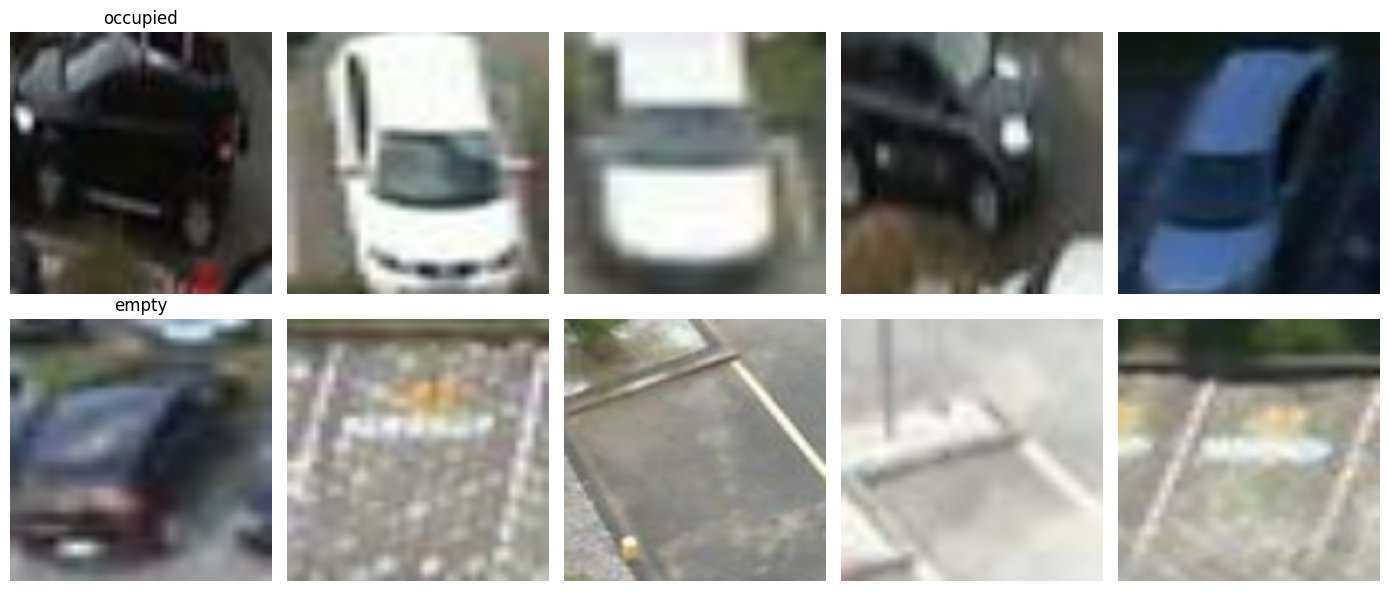

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for row, cls in enumerate(["occupied", "empty"]):
    sample_dir = OUT_ROOT / "train" / cls
    sample_files = sorted(os.listdir(sample_dir))[:5]
    for col, fname in enumerate(sample_files):
        img = cv2.cvtColor(cv2.imread(str(sample_dir / fname)), cv2.COLOR_BGR2RGB)
        axes[row, col].imshow(img)
        axes[row, col].set_title(cls if col == 0 else "")
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()

## Step 3 — Model Development\n\n### Data pipelines (with augmentation)

In [ ]:
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    OUT_ROOT / "train", image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode="binary", seed=42
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    OUT_ROOT / "val", image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode="binary", seed=42
)
test_ds = tf.keras.utils.image_dataset_from_directory(
    OUT_ROOT / "test", image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode="binary", shuffle=False
)

class_names = train_ds.class_names  # alphabetical: ['empty', 'occupied'] -> occupied = label 1
print("Class order (label 0 / 1):", class_names)

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomBrightness(0.15),
])

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.map(lambda x, y: (data_augmentation(x, training=True), y)).prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)


Found 560 files belonging to 2 classes.
Found 120 files belonging to 2 classes.
Found 120 files belonging to 2 classes.
Class order (label 0 / 1): ['empty', 'occupied']


### Build the MobileNetV2 transfer-learning model

In [ ]:
preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input

base_model = tf.keras.applications.MobileNetV2(
    input_shape=IMG_SIZE + (3,), include_top=False, weights="imagenet"
)
base_model.trainable = False  # freeze for the first training pass

inputs = tf.keras.Input(shape=IMG_SIZE + (3,))
x = preprocess_input(inputs)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
x = tf.keras.layers.Dense(128, activation="relu")(x)
x = tf.keras.layers.Dropout(0.2)(x)
outputs = tf.keras.layers.Dense(1, activation="sigmoid")(x)
model = tf.keras.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)
model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### Train (15–30 epochs per the brief, with early stopping)

In [ ]:
EPOCHS = 25

callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint("best_model.keras", monitor="val_accuracy", save_best_only=True),
]

history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks)


Epoch 1/25
18/18 ━━━━━━━━━━━━━━━━━━━━ 31s 1s/step - accuracy: 0.8268 - loss: 0.4068 - val_accuracy: 0.9667 - val_loss: 0.1584
Epoch 2/25
18/18 ━━━━━━━━━━━━━━━━━━━━ 5s 252ms/step - accuracy: 0.9393 - loss: 0.2316 - val_accuracy: 0.9750 - val_loss: 0.1505
Epoch 3/25
18/18 ━━━━━━━━━━━━━━━━━━━━ 5s 272ms/step - accuracy: 0.9500 - loss: 0.1799 - val_accuracy: 0.9750 - val_loss: 0.1383
Epoch 4/25
18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 217ms/step - accuracy: 0.9500 - loss: 0.1542 - val_accuracy: 0.9750 - val_loss: 0.1449
Epoch 5/25
18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 215ms/step - accuracy: 0.9589 - loss: 0.1361 - val_accuracy: 0.9750 - val_loss: 0.1478
Epoch 6/25
18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 221ms/step - accuracy: 0.9679 - loss: 0.1205 - val_accuracy: 0.9750 - val_loss: 0.1446
Epoch 7/25
18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 221ms/step - accuracy: 0.9625 - loss: 0.1293 - val_accuracy: 0.9750 - val_loss: 0.1172
Epoch 8/25
18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 224ms/step - accuracy: 0.9500 - loss: 0.1179 - val_accuracy: 0.97

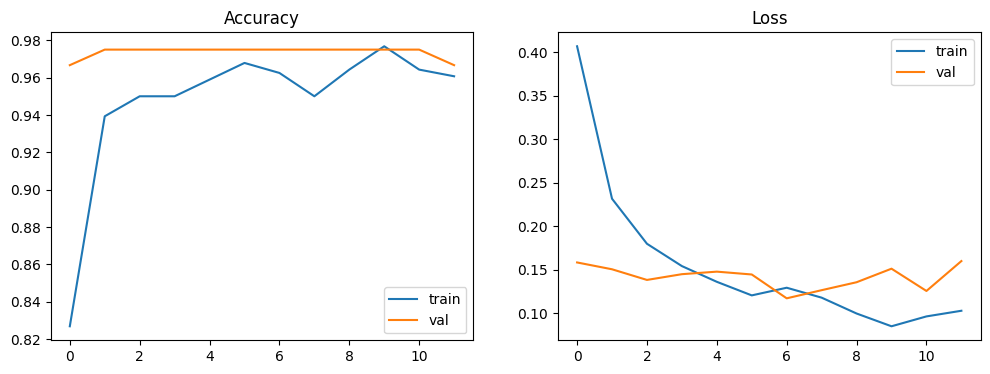

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["accuracy"], label="train")
axes[0].plot(history.history["val_accuracy"], label="val")
axes[0].set_title("Accuracy"); axes[0].legend()
axes[1].plot(history.history["loss"], label="train")
axes[1].plot(history.history["val_loss"], label="val")
axes[1].set_title("Loss"); axes[1].legend()
plt.show()


## Step 3 (cont.) — Evaluation on the held-out test set

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.9917 - loss: 0.0669
Test accuracy: 0.9917
4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step
              precision    recall  f1-score   support

       empty       1.00      0.98      0.99        60
    occupied       0.98      1.00      0.99        60

    accuracy                           0.99       120
   macro avg       0.99      0.99      0.99       120
weighted avg       0.99      0.99      0.99       120



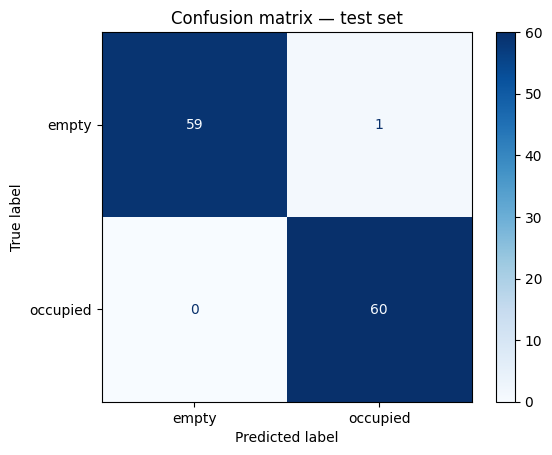

In [ ]:
test_loss, test_acc = model.evaluate(test_ds)
print(f"Test accuracy: {test_acc:.4f}")

y_true = np.concatenate([y.numpy() for _, y in test_ds]).astype(int).ravel()
y_prob = model.predict(test_ds).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print(classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap="Blues")
plt.title("Confusion matrix — test set")
plt.show()


### Optional: fine-tuning for a higher-accuracy / "Distinguished" rubric score

Unfreezes the top layers of MobileNetV2 and re-trains briefly at a much
lower learning rate. Skip this cell if your frozen-base accuracy already
looks solid and you're short on Colab GPU time.


In [ ]:
base_model.trainable = True
# keep the early, more generic layers frozen; only fine-tune the later ones
for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

fine_tune_history = model.fit(
    train_ds, validation_data=val_ds, epochs=10, callbacks=callbacks
)

test_loss, test_acc = model.evaluate(test_ds)
print(f"Test accuracy after fine-tuning: {test_acc:.4f}")


## Save the model for the Streamlit app

In [ ]:
MODEL_OUT = "parking_classifier.keras"
model.save(MODEL_OUT)
print(f"Saved {MODEL_OUT}")

# Download it, then drop it into parkvision-ai/model/parking_classifier.keras
# in your project repo (create the `model/` folder if it doesn't exist).
from google.colab import files
files.download(MODEL_OUT)


Saved parking_classifier.keras


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 4 preview — feeding predictions into the parking-insight logic

The congestion-level and recommendation rules (Step 4 of the brief) live in
`utils/insights.py` in the Streamlit project so the dashboard and this
notebook use the *exact same* logic — no risk of the two drifting apart.
Upload that one file here (or `pip install` nothing needed, it's dependency-free)
to sanity-check a batch of predictions end-to-end before moving to the app.


In [ ]:
from google.colab import files
print("Upload utils/insights.py from the project (optional, for this demo cell):")
uploaded = files.upload()


In [ ]:
import importlib.util
spec = importlib.util.spec_from_file_location("insights", "insights.py")
insights = importlib.util.module_from_spec(spec)
spec.loader.exec_module(insights)

# Treat one batch of test-set predictions as if they were N parking slots
demo_results = [
    insights.SlotResult(slot_id=i, occupied=bool(p), confidence=float(prob if p else 1 - prob))
    for i, (p, prob) in enumerate(zip(y_pred[:20], y_prob[:20]))
]
summary = insights.summarize_lot(demo_results)
print(summary)


## Next steps

1. **Step 5 (Streamlit app):** `app.py` in the project repo already does the
   slot-crop -> classify -> overlay -> insights pipeline — just drop your
   saved `parking_classifier.keras` into its `model/` folder.
2. **Define real slot coordinates:** run `slot_position_picker.py` on a
   reference photo of the lot you'll demo with, to produce a
   `slot_positions.json` for `app.py` (the bundled demo one is synthetic).
3. **Step 6 (testing):** try `app.py` against unseen lot photos — different
   lighting/weather/angle — and note failure cases in the README.
4. **Step 7 (deployment):** push the repo to GitHub and deploy on
   [Streamlit Cloud](https://streamlit.io/cloud). See the project README for
   the full checklist.


In [ ]:
import json, cv2, random
from pathlib import Path
from google.colab import files

folder = Path("/content/pklot_raw/test")
coco = json.load(open(next(folder.glob("*.json"))))
cat_names = {c["id"]: c["name"].lower() for c in coco["categories"]}

# pick a test photo that has plenty of labelled slots
counts = {}
for a in coco["annotations"]:
    if "space-" in cat_names[a["category_id"]]:
        counts[a["image_id"]] = counts.get(a["image_id"], 0) + 1
image_id = random.Random(1).choice([i for i, n in counts.items() if n >= 20])
im = next(i for i in coco["images"] if i["id"] == image_id)

positions, truth = [], []
for a in coco["annotations"]:
    name = cat_names[a["category_id"]]
    if a["image_id"] == image_id and "space-" in name:
        x, y, w, h = [int(v) for v in a["bbox"]]
        positions.append({"id": len(positions), "x": max(x, 0), "y": max(y, 0), "w": w, "h": h})
        truth.append("occupied" if "occupied" in name else "empty")

img = cv2.imread(str(folder / im["file_name"]))
cv2.imwrite("real_lot.jpg", img)
json.dump(positions, open("real_slot_positions.json", "w"), indent=2)
print(f"{len(positions)} slots, truly occupied: {truth.count('occupied')}, truly empty: {truth.count('empty')}")
files.download("real_lot.jpg")
files.download("real_slot_positions.json")

40 slots, truly occupied: 28, truly empty: 12


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!ls /content

sample_data
